# Kappa Foundation — BFIN WS2026 Group Assignment
**Reproducible starter notebook | Case decision date: 31 Dec 2022**

This notebook downloads its own market/factor data, saves untouched downloads, and creates named outputs. Run top-to-bottom. Internet is required only for the retrieval cells; after raw data have been saved, set `DOWNLOAD_DATA = False` to rebuild analysis offline.

**Important:** The case does not specify inflation, expected returns, risk aversion, or a benchmark. Defaults below are explicit *working assumptions*, not facts from the case. The group must approve/freeze them in the 22 October decision record. The case bonds are fictional: do not download or invent historical bond prices.

## Cell 1 — Setup, assumptions, reproducibility
Install packages first if needed: `pip install -r requirements.txt`.

Folders created: `data/raw/`, `data/processed/`, `outputs/`. Every generated table/figure is saved with a stable filename.

In [112]:
from pathlib import Path
import sys, os, json, zipfile, io, re, warnings, platform, subprocess
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import scipy
from scipy.optimize import minimize, brentq
import statsmodels.api as sm

SEED = 42
np.random.seed(SEED)

BASE = Path.cwd()
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
OUT = BASE / "outputs"
for folder in (RAW, PROCESSED, OUT):
    folder.mkdir(parents=True, exist_ok=True)

# Case facts: decision date 31-Dec-2022; all amounts in USD.
INITIAL_CASH = 12_000_000
PAYMENTS = {2: 2_400_000, 5: 3_600_000}  # years from 31-Dec-2022
REAL_GOAL_2030 = 8_000_000
INFLATION_BASE = 0.025  # illustrative only; trustees did not specify inflation
EST_START = "2015-01-31"
EST_END = "2022-12-31"
EVAL_START = "2023-01-31"
EVAL_END = "2025-12-31"
DOWNLOAD_DATA = True

# Provisional investment policy assumptions; justify or change before submission.
MAX_WEIGHT = 0.25
RISK_AVERSION_GRID = [2.0, 5.0, 10.0]
CHOSEN_GAMMA = 5.0
PARALLEL_RATE_SHOCK = 0.01
CURVE_SHORT_SHOCK = 0.01
CURVE_LONG_SHOCK = -0.005

VERSION_RECORD = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "scipy": scipy.__version__,
    "statsmodels": sm.__version__,
    "download_data": DOWNLOAD_DATA,
    "case_decision_date": "2022-12-31",
    "estimation_window": [EST_START, EST_END],
    "evaluation_window": [EVAL_START, EVAL_END],
    "inflation_assumption": INFLATION_BASE,
}
(OUT / "environment_and_assumptions.json").write_text(json.dumps(VERSION_RECORD, indent=2))
print(json.dumps(VERSION_RECORD, indent=2))

{
  "retrieved_at_utc": "2026-10-19T15:45:41.988102+00:00",
  "python": "3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26300-SP0",
  "pandas": "3.0.6",
  "numpy": "2.5.4",
  "yfinance": "1.7.0",
  "scipy": "1.18.1",
  "statsmodels": "0.15.0",
  "download_data": true,
  "case_decision_date": "2022-12-31",
  "estimation_window": [
    "2015-01-31",
    "2022-12-31"
  ],
  "evaluation_window": [
    "2023-01-31",
    "2025-12-31"
  ],
  "inflation_assumption": 0.025
}


In [113]:
import pandas as pd
from pathlib import Path

file_path = Path("outputs/initial_funding_plan.csv")
df = pd.read_csv(file_path)

display(df)


,asset,face_or_units,initial_cost,contractual_maturity_cashflow,payment_obligation,surplus_at_maturity
0,Beta zero-coupon,2400000.0,2214672.0,2400000.0,2400000.0,0.0
1,Delta 3.5% coupon,3600000.0,3549852.0,3600000.0,3600000.0,0.0
2,Growth allocation,NaN,6235476.0,NaN,0.0,NaN


In [114]:

# Annual contractual cash flows from the two bonds
delta_coupon_rate = float(
    BONDS.loc[BONDS.bond.eq("Delta"), "coupon"].iloc[0]
)

beta_face = PAYMENTS[2]
delta_face = PAYMENTS[5]
delta_coupon = delta_face * delta_coupon_rate

cashflow_rows = []

for year in range(1, 9):
    calendar_year = 2022 + year

    beta_principal = beta_face if year == 2 else 0
    delta_principal = delta_face if year == 5 else 0

    # Delta pays annual coupons from 2023 through 2027
    delta_coupon_payment = delta_coupon if year <= 5 else 0

    total_bond_cashflow = (
        beta_principal + delta_principal + delta_coupon_payment
    )

    payment_obligation = PAYMENTS.get(year, 0)

    cashflow_rows.append({
        "year": calendar_year,
        "beta_principal": beta_principal,
        "delta_principal": delta_principal,
        "delta_coupon": delta_coupon_payment,
        "total_bond_cashflow": total_bond_cashflow,
        "payment_obligation": payment_obligation,
        "net_cashflow_before_reinvestment": (
            total_bond_cashflow - payment_obligation
        ),
    })

annual_funding = pd.DataFrame(cashflow_rows)

display(annual_funding)

annual_funding.to_csv(
    OUT / "annual_bond_cashflows.csv",
    index=False
)


,year,beta_principal,delta_principal,delta_coupon,total_bond_cashflow,payment_obligation,net_cashflow_before_reinvestment
0,2023,0,0,126000.0,126000.0,0,126000.0
1,2024,2400000,0,126000.0,2526000.0,2400000,126000.0
2,2025,0,0,126000.0,126000.0,0,126000.0
3,2026,0,0,126000.0,126000.0,0,126000.0
4,2027,0,3600000,126000.0,3726000.0,3600000,126000.0
5,2028,0,0,0.0,0.0,0,0.0
6,2029,0,0,0.0,0.0,0,0.0
7,2030,0,0,0.0,0.0,0,0.0


In [115]:

# Recalculate and display the annual cash-flow table clearly
annual_funding["total_bond_cashflow"] = (
    annual_funding["beta_principal"]
    + annual_funding["delta_principal"]
    + annual_funding["delta_coupon"]
)

annual_funding["net_cashflow_before_reinvestment"] = (
    annual_funding["total_bond_cashflow"]
    - annual_funding["payment_obligation"]
)

display(annual_funding)


,year,beta_principal,delta_principal,delta_coupon,total_bond_cashflow,payment_obligation,net_cashflow_before_reinvestment
0,2023,0,0,126000.0,126000.0,0,126000.0
1,2024,2400000,0,126000.0,2526000.0,2400000,126000.0
2,2025,0,0,126000.0,126000.0,0,126000.0
3,2026,0,0,126000.0,126000.0,0,126000.0
4,2027,0,3600000,126000.0,3726000.0,3600000,126000.0
5,2028,0,0,0.0,0.0,0,0.0
6,2029,0,0,0.0,0.0,0,0.0
7,2030,0,0,0.0,0.0,0,0.0


In [116]:

print(annual_funding.to_string(index=False))


 year  beta_principal  delta_principal  delta_coupon  total_bond_cashflow  payment_obligation  net_cashflow_before_reinvestment
 2023               0                0      126000.0             126000.0                   0                          126000.0
 2024         2400000                0      126000.0            2526000.0             2400000                          126000.0
 2025               0                0      126000.0             126000.0                   0                          126000.0
 2026               0                0      126000.0             126000.0                   0                          126000.0
 2027               0          3600000      126000.0            3726000.0             3600000                          126000.0
 2028               0                0           0.0                  0.0                   0                               0.0
 2029               0                0           0.0                  0.0                   0           

## Cell 2 — Define the candidate universe and benchmark

10 US common stocks across more than four sectors, plus two equity ETFs with different mandates. The universe is a starting point, not proof of point-in-time eligibility. Add archived issuer/exchange evidence dated on or before 31-Dec-2022 to the decision record. The selection is retrospective and survivors may introduce selection bias.

In [117]:
from pathlib import Path
import pandas as pd
from IPython.display import display

for file_path in sorted(Path("outputs").glob("*.csv")):
    print(f"\n📊 {file_path.name}")
    display(pd.read_csv(file_path))
    


📊 annual_bond_cashflows.csv


,year,beta_principal,delta_principal,delta_coupon,total_bond_cashflow,payment_obligation,net_cashflow_before_reinvestment
0,2023,0,0,126000.0,126000.0,0,126000.0
1,2024,2400000,0,126000.0,2526000.0,2400000,126000.0
2,2025,0,0,126000.0,126000.0,0,126000.0
3,2026,0,0,126000.0,126000.0,0,126000.0
4,2027,0,3600000,126000.0,3726000.0,3600000,126000.0
5,2028,0,0,0.0,0.0,0,0.0
6,2029,0,0,0.0,0.0,0,0.0
7,2030,0,0,0.0,0.0,0,0.0



📊 bond_curve_shape_stress.csv


,bond,quoted_price,scenario_base_price,parallel_up_100bp_price,parallel_up_change,curve_twist_price,curve_twist_change
0,Alpha,958.77,958.770000,949.664898,-0.009497,949.664898,-0.009497
1,Beta,922.78,922.780000,905.303509,-0.018939,909.006429,-0.014926
2,Gamma,1002.49,997.155174,970.026761,-0.027206,981.223746,-0.015977
3,Delta,986.07,973.297460,930.854292,-0.043608,965.800609,-0.007703
4,Epsilon,1040.71,1026.734120,961.292807,-0.063737,1054.842248,0.027376



📊 bond_valuation_duration_convexity.csv


...

,gamma,risk_model,expected_return_ann,volatility_ann,largest_weight,largest_holding,weight_SPY,weight_IWM,number_of_positions_over_5pct
0,0.5,Sample covariance,0.237525,0.201162,0.25,AAPL,8.174271e-17,1.161569e-18,5
1,0.5,Single-index,0.237029,0.186640,0.25,AAPL,1.459623e-16,7.005374e-17,4
2,1.0,Sample covariance,0.237295,0.199438,0.25,AAPL,1.382358e-16,4.745252e-18,5
3,1.0,Single-index,0.237029,0.186640,0.25,AAPL,0.000000e+00,1.759082e-16,4
4,1.5,Sample covariance,0.237218,0.199117,0.25,AAPL,0.000000e+00,9.589610e-18,4
5,1.5,Single-index,0.237029,0.186640,0.25,MSFT,2.621603e-16,3.800258e-17,4
6,2.0,Sample covariance,0.237179,0.199005,0.25,MSFT,0.000000e+00,1.032952e-16,4
7,2.0,Single-index,0.237029,0.186640,0.25,AAPL,0.000000e+00,9.974900e-17,4
8,2.5,Sample covariance,0.233995,0.192032,0.25,MSFT,1.450268e-16,0.000000e+00,4
9,2.5,Single-index,0.237029,0.186640,0.25,MSFT,0.000000e+00,0.000000e+00,4



📊 risk_return_preference_comparison.csv


,asset,gamma,expected_return_ann,volatility_ann,variance_ann,utility
0,AAPL,2.0,0.250105,0.291295,0.084853,0.165252
1,AAPL,5.0,0.250105,0.291295,0.084853,0.037973
2,AAPL,10.0,0.250105,0.291295,0.084853,-0.174158
3,MSFT,2.0,0.248767,0.224986,0.050619,0.198148
4,MSFT,5.0,0.248767,0.224986,0.050619,0.122220
5,MSFT,10.0,0.248767,0.224986,0.050619,-0.004327
6,JPM,2.0,0.155731,0.253863,0.064447,0.091284
7,JPM,5.0,0.155731,0.253863,0.064447,-0.005385
8,JPM,10.0,0.155731,0.253863,0.064447,-0.166502
9,XOM,2.0,0.109082,0.289409,0.083758,0.025324



📊 sample_coverage.csv


,period,start,end,common_months
0,Estimation,2015-01-31,2022-12-31,96
1,Evaluation,2023-01-31,2025-12-31,36


In [118]:
STOCKS = {
    "AAPL": "Information Technology",
    "MSFT": "Information Technology",
    "JPM": "Financials",
    "XOM": "Energy",
    "JNJ": "Health Care",
    "PG": "Consumer Staples",
    "CAT": "Industrials",
    "AMZN": "Consumer Discretionary",
    "NEE": "Utilities",
    "DIS": "Communication Services",
}
ETFS = {
    "SPY": "Broad US large-cap equity benchmark",
    "IWM": "US small-cap equity exposure",
}
TICKERS = list(STOCKS) + list(ETFS)
BENCHMARK = "SPY"
UNIVERSE_RECORD = pd.DataFrame(
    [{"ticker": t, "role": role, "type": "Stock" if t in STOCKS else "ETF"}
     for t, role in {**STOCKS, **ETFS}.items()]
)
UNIVERSE_RECORD.to_csv(OUT / "candidate_universe.csv", index=False)
UNIVERSE_RECORD

,ticker,role,type
0,AAPL,Information Technology,Stock
1,MSFT,Information Technology,Stock
2,JPM,Financials,Stock
3,XOM,Energy,Stock
4,JNJ,Health Care,Stock
5,PG,Consumer Staples,Stock
6,CAT,Industrials,Stock
7,AMZN,Consumer Discretionary,Stock
8,NEE,Utilities,Stock
9,DIS,Communication Services,Stock


## Cell 3 — Download adjusted market prices from Yahoo Finance

Download daily adjusted prices from Dec-2014 through Dec-2025 so monthly returns include January 2015. `auto_adjust=True` adjusts for splits/dividends. Save the untransformed yfinance response and metadata before constructing returns.

In [119]:
PRICE_FILE = RAW / "yfinance_daily_adjusted_close.csv"
YF_META_FILE = RAW / "yfinance_download_metadata.json"

if DOWNLOAD_DATA:
    yf_response = yf.download(
        TICKERS, start="2014-12-01", end="2026-01-01",
        interval="1d", auto_adjust=True, actions=False,
        group_by="column", progress=False, threads=True
    )
    if yf_response.empty:
        raise RuntimeError("Yahoo Finance returned no rows. Check internet, ticker eligibility, or retry.")
    # Keep the downloaded response as-is (column names are flattened only for CSV export).
    yf_response.to_csv(PRICE_FILE)
    YF_META_FILE.write_text(json.dumps({
        "source": "Yahoo Finance via yfinance",
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "tickers": TICKERS, "start_inclusive": "2014-12-01",
        "end_exclusive": "2026-01-01", "interval": "1d",
        "auto_adjust": True, "actions": False,
        "yfinance_version": yf.__version__,
        "note": "CSV stores the downloaded DataFrame; adjusted OHLC fields if returned."
    }, indent=2))
    # Use adjusted Close from the in-memory download.
    if isinstance(yf_response.columns, pd.MultiIndex):
        if "Close" in yf_response.columns.get_level_values(0):
            daily_prices = yf_response["Close"].copy()
        else:
            raise RuntimeError("Expected adjusted Close column missing from Yahoo response.")
    else:
        daily_prices = yf_response[["Close"]].rename(columns={"Close": TICKERS[0]})
else:
    # CSV export from yfinance MultiIndex may have two header rows.
    raw = pd.read_csv(PRICE_FILE, header=[0,1], index_col=0, parse_dates=True)
    if isinstance(raw.columns, pd.MultiIndex) and "Close" in raw.columns.get_level_values(0):
        daily_prices = raw["Close"].copy()
    else:
        raise RuntimeError("Offline reload could not identify Close columns; keep the saved original download.")

daily_prices.index = pd.to_datetime(daily_prices.index)
daily_prices = daily_prices.sort_index()
monthly_prices = daily_prices.resample("ME").last()
monthly_returns = monthly_prices.pct_change(fill_method=None).dropna(how="all")
monthly_prices.to_csv(PROCESSED / "monthly_adjusted_prices.csv")
monthly_returns.to_csv(PROCESSED / "monthly_total_returns.csv")
print("Daily rows:", len(daily_prices), "| monthly return rows:", len(monthly_returns))
print("Missing returns by ticker:\n", monthly_returns.isna().sum())

Daily rows: 2788 | monthly return rows: 132
Missing returns by ticker:
 Ticker
AAPL    0
AMZN    0
CAT     0
DIS     0
IWM     0
JNJ     0
JPM     0
MSFT    0
NEE     0
PG      0
SPY     0
XOM     0
dtype: int64


## Cell 4 — Retrieve Kenneth French monthly factors

Use the Fama/French 5 Factors (2x3) and Momentum factor files. Preserve the original ZIP downloads and record exact URLs/retrieval date. Factor data are published in percent units and are converted to decimal returns below. Parsing is defensive because the files contain explanatory headers and footers.

In [120]:
FF5_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_CSV.zip"
MOM_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Momentum_Factor_CSV.zip"

def download_zip(url, destination):
    import urllib.request
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as response:
        payload = response.read()
    destination.write_bytes(payload)
    return payload

def parse_french_monthly_csv(zip_bytes, expected_columns):
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        csv_names = [n for n in zf.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise ValueError("No CSV found in French ZIP archive.")
        text_csv = zf.read(csv_names[0]).decode("latin1")
    lines = text_csv.splitlines()
    start = None
    for i, line in enumerate(lines):
        first = line.strip().split(",")[0].strip().strip('"')
        if re.fullmatch(r"\d{6}", first):
            start = i
            break
    if start is None:
        raise ValueError("Could not locate YYYYMM data rows in French file.")
    rows = []
    for line in lines[start:]:
        parts = [p.strip().strip('"') for p in line.split(",")]
        if not parts or not re.fullmatch(r"\d{6}", parts[0]):
            break
        if len(parts) >= len(expected_columns) + 1:
            rows.append(parts[:len(expected_columns)+1])
    df = pd.DataFrame(rows, columns=["YYYYMM"] + expected_columns)
    df["Date"] = pd.to_datetime(df["YYYYMM"], format="%Y%m") + pd.offsets.MonthEnd(0)
    df = df.set_index("Date").drop(columns="YYYYMM")
    for col in expected_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce") / 100.0
    return df

if DOWNLOAD_DATA:
    ff5_bytes = download_zip(FF5_URL, RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip")
    mom_bytes = download_zip(MOM_URL, RAW / "F-F_Momentum_Factor_CSV.zip")
    (RAW / "french_download_metadata.json").write_text(json.dumps({
        "source": "Kenneth French Data Library",
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "files": [
            {"url": FF5_URL, "saved_as": "F-F_Research_Data_5_Factors_2x3_CSV.zip"},
            {"url": MOM_URL, "saved_as": "F-F_Momentum_Factor_CSV.zip"}
        ],
        "units_in_download": "percent per month; converted to decimal in processed data"
    }, indent=2))
else:
    ff5_bytes = (RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").read_bytes()
    mom_bytes = (RAW / "F-F_Momentum_Factor_CSV.zip").read_bytes()

ff5 = parse_french_monthly_csv(ff5_bytes, ["Mkt-RF","SMB","HML","RMW","CMA","RF"])
mom = parse_french_monthly_csv(mom_bytes, ["Mom"])
factors = ff5.join(mom, how="inner").sort_index()
factors.to_csv(PROCESSED / "kenneth_french_monthly_factors_decimal.csv")
print(factors.head())
print("Factor coverage:", factors.index.min().date(), "to", factors.index.max().date())

            Mkt-RF     SMB     HML     RMW     CMA      RF     Mom
Date                                                              
1963-07-31 -0.0039 -0.0048 -0.0084  0.0064 -0.0115  0.0027  0.0101
1963-08-31  0.0508 -0.0080  0.0172  0.0040 -0.0038  0.0025  0.0100
1963-09-30 -0.0157 -0.0043 -0.0002 -0.0078  0.0015  0.0027  0.0012
1963-10-31  0.0254 -0.0134 -0.0003  0.0279 -0.0225  0.0029  0.0313
1963-11-30 -0.0086 -0.0085  0.0178 -0.0043  0.0227  0.0027 -0.0077
Factor coverage: 1963-07-31 to 2026-08-31


## Cell 5 — Validate the common estimation/evaluation samples

The estimation window ends in December 2022. The evaluation window is not used to estimate expected returns, optimize weights, or select the strategy. Report common observations and missing data rather than filling missing values with invented returns.

In [121]:
est_start = pd.Timestamp("2015-01-01")
est_end = pd.Timestamp("2022-12-31")
eval_start = pd.Timestamp("2023-01-01")
eval_end = pd.Timestamp("2025-12-31")

asset_returns = monthly_returns.loc[:, TICKERS].copy()
common = asset_returns.join(factors, how="inner")
est = common.loc[(common.index >= est_start) & (common.index <= est_end)].copy()
evaluation = common.loc[(common.index >= eval_start) & (common.index <= eval_end)].copy()

# Keep a strict common sample for fair covariance/model comparisons.
est = est.dropna(subset=TICKERS + ["Mkt-RF","RF","SMB","HML","RMW","CMA","Mom"])
evaluation = evaluation.dropna(subset=TICKERS + ["Mkt-RF","RF","SMB","HML","RMW","CMA","Mom"])

if len(est) < 60:
    raise ValueError(f"Only {len(est)} common monthly observations in estimation window; need at least 60.")
if len(evaluation) < 30:
    warnings.warn(f"Evaluation window has {len(evaluation)} common months; expected about 36.")

coverage = pd.DataFrame({
    "period": ["Estimation", "Evaluation"],
    "start": [est.index.min().date(), evaluation.index.min().date()],
    "end": [est.index.max().date(), evaluation.index.max().date()],
    "common_months": [len(est), len(evaluation)]
})
coverage.to_csv(OUT / "sample_coverage.csv", index=False)
coverage

,period,start,end,common_months
0,Estimation,2015-01-31,2022-12-31,96
1,Evaluation,2023-01-31,2025-12-31,36


## Cell 6 — Bond valuation, YTM, duration and convexity

Use the case quotes only. Annual coupon cash flows are paid each 31 December; settlement follows the 2022 coupon date, so accrued interest is zero. Duration/convexity are computed from the bond's own YTM and checked against exact repricing. The supplied information is not a complete spot curve.

In [122]:
BONDS = pd.DataFrame([
    {"bond":"Alpha", "maturity":1, "coupon":0.0000, "price":958.77},
    {"bond":"Beta", "maturity":2, "coupon":0.0000, "price":922.78},
    {"bond":"Gamma", "maturity":3, "coupon":0.0400, "price":1002.49},
    {"bond":"Delta", "maturity":5, "coupon":0.0350, "price":986.07},
    {"bond":"Epsilon", "maturity":8, "coupon":0.0450, "price":1040.71},
])
FACE = 1000.0

def bond_cashflows(face, coupon_rate, maturity):
    times = np.arange(1, maturity + 1, dtype=float)
    cf = np.full(maturity, face * coupon_rate)
    cf[-1] += face
    return times, cf

def price_from_yield(y, face, coupon_rate, maturity):
    t, cf = bond_cashflows(face, coupon_rate, maturity)
    return float(np.sum(cf / (1+y)**t))

def ytm_from_price(price, face, coupon_rate, maturity):
    return brentq(lambda y: price_from_yield(y, face, coupon_rate, maturity)-price, -0.95, 2.0)

def bond_metrics(row):
    y = ytm_from_price(row.price, FACE, row.coupon, int(row.maturity))
    t, cf = bond_cashflows(FACE, row.coupon, int(row.maturity))
    pv = cf / (1+y)**t
    macaulay = np.sum(t * pv) / row.price
    mod_duration = macaulay / (1+y)
    convexity = np.sum(cf * t * (t+1) / (1+y)**(t+2)) / row.price
    up = price_from_yield(y + PARALLEL_RATE_SHOCK, FACE, row.coupon, int(row.maturity))
    down = price_from_yield(y - PARALLEL_RATE_SHOCK, FACE, row.coupon, int(row.maturity))
    duration_approx_up = row.price * (-mod_duration*PARALLEL_RATE_SHOCK + 0.5*convexity*PARALLEL_RATE_SHOCK**2)
    duration_approx_down = row.price * (mod_duration*PARALLEL_RATE_SHOCK + 0.5*convexity*PARALLEL_RATE_SHOCK**2)
    return pd.Series({
        "ytm": y, "macaulay_duration": macaulay, "modified_duration": mod_duration,
        "convexity": convexity, "price_if_yield_plus_100bp": up,
        "exact_change_plus_100bp": up/row.price-1,
        "duration_convexity_change_plus_100bp": duration_approx_up/row.price,
        "price_if_yield_minus_100bp": down,
        "exact_change_minus_100bp": down/row.price-1,
        "duration_convexity_change_minus_100bp": duration_approx_down/row.price
    })

bond_results = pd.concat([BONDS, BONDS.apply(bond_metrics, axis=1)], axis=1)
bond_results.to_csv(OUT / "bond_valuation_duration_convexity.csv", index=False)
bond_results

,bond,maturity,coupon,price,ytm,macaulay_duration,modified_duration,convexity,price_if_yield_plus_100bp,exact_change_plus_100bp,duration_convexity_change_plus_100bp,price_if_yield_minus_100bp,exact_change_minus_100bp,duration_convexity_change_minus_100bp
0,Alpha,1,0.000,958.77,0.043003,1.000000,0.958770,1.838480,949.664898,-0.009497,-0.009496,968.051386,0.009681,0.009680
1,Beta,2,0.000,922.78,0.041000,2.000000,1.921229,5.536680,905.303509,-0.018939,-0.018935,940.767483,0.019493,0.019489
2,Gamma,3,0.040,1002.49,0.039104,2.886248,2.777631,10.552827,975.165177,-0.027257,-0.027249,1030.872976,0.028312,0.028304
3,Delta,5,0.035,986.07,0.038112,4.670411,4.498945,25.402287,942.932378,-0.043747,-0.043719,1031.713530,0.046288,0.046260
4,Epsilon,8,0.045,1040.71,0.038979,6.918166,6.658620,54.785467,974.177034,-0.063930,-0.063847,1112.949189,0.069413,0.069325


## Cell 7 — Fund the mandatory payments with case bonds

A transparent candidate is to buy enough Beta face value to pay $2.4m in year 2 and enough Delta face value to pay $3.6m in year 5. Delta coupons are surplus cash flows; the year-5 final payment is $3.726m, leaving $126k after the $3.6m obligation. Bond prices are per $1,000 face, so purchases are fractional.

In [123]:
beta_face = PAYMENTS[2]  # zero-coupon face amount matures at $2.4m
delta_face = PAYMENTS[5]  # principal alone meets $3.6m; coupon is extra
beta_cost = beta_face / FACE * float(BONDS.loc[BONDS.bond.eq("Beta"), "price"].iloc[0])
delta_cost = delta_face / FACE * float(BONDS.loc[BONDS.bond.eq("Delta"), "price"].iloc[0])
bond_cost = beta_cost + delta_cost
growth_capital = INITIAL_CASH - bond_cost


delta_coupon_rate = float(
    BONDS.loc[BONDS.bond.eq("Delta"), "coupon"].iloc[0]
)
delta_annual_coupon = delta_face * delta_coupon_rate

funding_summary = pd.DataFrame([
    {
        "asset": "Beta zero-coupon",
        "face_or_units": beta_face,
        "initial_cost": beta_cost,
        "contractual_maturity_cashflow": beta_face,
        "payment_obligation": PAYMENTS[2],
        "surplus_at_maturity": 0.0,
    },
    {
        "asset": "Delta 3.5% coupon",
        "face_or_units": delta_face,
        "initial_cost": delta_cost,
        "contractual_maturity_cashflow": delta_face,
        "payment_obligation": PAYMENTS[5],
        "surplus_at_maturity": 0.0,
    },
    {
        "asset": "Growth allocation",
        "face_or_units": np.nan,
        "initial_cost": growth_capital,
        "contractual_maturity_cashflow": np.nan,
        "payment_obligation": 0.0,
        "surplus_at_maturity": np.nan,
    },
])

funding_summary.to_csv(OUT / "initial_funding_plan.csv", index=False)

print(f"Beta cost: ${beta_cost:,.2f}")
print(f"Delta cost: ${delta_cost:,.2f}")
print(f"Delta annual coupon: ${delta_annual_coupon:,.2f}")
print(f"Remaining for growth allocation: ${growth_capital:,.2f}")
print(f"Check total: ${bond_cost + growth_capital:,.2f}")

display(funding_summary)


Beta cost: $2,214,672.00
Delta cost: $3,549,852.00
Delta annual coupon: $126,000.00
Remaining for growth allocation: $6,235,476.00
Check total: $12,000,000.00


,asset,face_or_units,initial_cost,contractual_maturity_cashflow,payment_obligation,surplus_at_maturity
0,Beta zero-coupon,2400000.0,2214672.0,2400000.0,2400000.0,0.0
1,Delta 3.5% coupon,3600000.0,3549852.0,3600000.0,3600000.0,0.0
2,Growth allocation,NaN,6235476.0,NaN,0.0,NaN


## Cell 8 — Incomplete term structure and curve-shape stress

The case provides two zero-coupon quotes (1y and 2y), not a complete spot curve. Do not pretend coupon-bond YTMs are spot rates. For a transparent *scenario*, infer 1y/2y zero rates from Alpha/Beta prices, then extend a flat terminal spot rate to 3–8 years as a simplifying assumption. Stress the curve by adding +100bp at the short end and −50bp at the long end, interpolated linearly by maturity. This is a sensitivity scenario, not a uniquely identified market curve.

In [124]:
zero_quotes = BONDS[BONDS.bond.isin(["Alpha","Beta"])].copy()
zero_quotes["spot_rate"] = (FACE / zero_quotes["price"])**(1/zero_quotes["maturity"]) - 1
r1 = float(zero_quotes.loc[zero_quotes.maturity.eq(1),"spot_rate"].iloc[0])
r2 = float(zero_quotes.loc[zero_quotes.maturity.eq(2),"spot_rate"].iloc[0])
base_spot = {1:r1, 2:r2}
for mat in range(3, 9):
    base_spot[mat] = r2  # explicit flat extension beyond observed zero quotes

def price_from_spot_curve(coupon_rate, maturity, face=1000.0, curve=None):
    times, cf = bond_cashflows(face, coupon_rate, maturity)
    return float(sum(cf_i/(1+curve[int(t)])**t for t, cf_i in zip(times, cf)))

def shock_curve(curve, short_shock=0.01, long_shock=-0.005):
    # Linear shock profile: +100bp at 1y, gradually reaching -50bp at 8y.
    out = {}
    for t, rate in curve.items():
        weight = (t-1)/(8-1)
        out[t] = rate + short_shock*(1-weight) + long_shock*weight
    return out

curve_up = {t:r+PARALLEL_RATE_SHOCK for t,r in base_spot.items()}
curve_twist = shock_curve(base_spot, CURVE_SHORT_SHOCK, CURVE_LONG_SHOCK)
curve_rows = []
for _, row in BONDS.iterrows():
    base_p = price_from_spot_curve(row.coupon, int(row.maturity), curve=base_spot)
    parallel_p = price_from_spot_curve(row.coupon, int(row.maturity), curve=curve_up)
    twist_p = price_from_spot_curve(row.coupon, int(row.maturity), curve=curve_twist)
    curve_rows.append({"bond":row.bond, "quoted_price":row.price, "scenario_base_price":base_p,
                       "parallel_up_100bp_price":parallel_p, "parallel_up_change":parallel_p/base_p-1,
                       "curve_twist_price":twist_p, "curve_twist_change":twist_p/base_p-1})
curve_stress = pd.DataFrame(curve_rows)
curve_stress.to_csv(OUT / "bond_curve_shape_stress.csv", index=False)
print("Observed zero rates:", {"1y":r1, "2y":r2})
curve_stress

Observed zero rates: {'1y': 0.04300301427871123, '2y': 0.04100044077008991}


,bond,quoted_price,scenario_base_price,parallel_up_100bp_price,parallel_up_change,curve_twist_price,curve_twist_change
0,Alpha,958.77,958.770000,949.664898,-0.009497,949.664898,-0.009497
1,Beta,922.78,922.780000,905.303509,-0.018939,909.006429,-0.014926
2,Gamma,1002.49,997.155174,970.026761,-0.027206,981.223746,-0.015977
3,Delta,986.07,973.297460,930.854292,-0.043608,965.800609,-0.007703
4,Epsilon,1040.71,1026.734120,961.292807,-0.063737,1054.842248,0.027376


## Cell 9 — Real-value goal and required growth return

Inflation is unspecified, so show sensitivity rather than treating 2.5% as known. The required-return calculation compounds the growth allocation and reinvests Delta's annual coupon cash flows and year-5 surplus at the same hypothetical growth return. It assumes the Beta and Delta principal payments meet the obligations exactly. This is a scenario calculation, not a guarantee; reinvestment risk and the path of returns remain.

In [125]:
def terminal_value_given_return(r, growth_capital, delta_face, coupon_rate=0.035):
    # Growth capital compounds 8 years; Delta pays annual coupons in years 1-5.
    coupons = delta_face * coupon_rate
    return growth_capital*(1+r)**8 + sum(coupons*(1+r)**(8-t) for t in range(1,6))

def required_return_for_inflation(inflation):
    target = REAL_GOAL_2030*(1+inflation)**8
    f = lambda r: terminal_value_given_return(r, growth_capital, delta_face)-target
    try:
        req = brentq(f, -0.90, 1.0)
    except ValueError:
        req = np.nan
    return {"annual_inflation":inflation, "nominal_2030_target":target,
            "required_growth_return":req}

inflation_sensitivity = pd.DataFrame([required_return_for_inflation(i) for i in [0.00,0.02,0.025,0.03,0.04]])
inflation_sensitivity.to_csv(OUT / "inflation_goal_sensitivity.csv", index=False)
inflation_sensitivity

,annual_inflation,nominal_2030_target,required_growth_return
0,0.000,8.000000e+06,0.019972
1,0.020,9.373275e+06,0.041033
2,0.025,9.747223e+06,0.046293
3,0.030,1.013416e+07,0.051551
4,0.040,1.094855e+07,0.062062


## Cell 10 — Risk–return preference comparison

Compare annualized expected return minus a risk penalty, `U = E[R] − 0.5 × gamma × variance`. This is a decision aid, not a universal utility model. Because the case gives no risk-aversion parameter, show several gamma values and explain the effect on allocation. Historical sample means are noisy; do not describe them as reliable forecasts.

In [126]:
R_EST = est[TICKERS].copy()
mu_ann = R_EST.mean() * 12
cov_sample_ann = R_EST.cov() * 12

def utility_table(mu, cov, gamma_values):
    rows=[]
    for ticker in mu.index:
        vol = np.sqrt(max(cov.loc[ticker,ticker],0))
        for gamma in gamma_values:
            utility = mu[ticker] - 0.5*gamma*cov.loc[ticker,ticker]
            rows.append({"asset":ticker,"gamma":gamma,"expected_return_ann":mu[ticker],
                         "volatility_ann":vol,"variance_ann":cov.loc[ticker,ticker],"utility":utility})
    return pd.DataFrame(rows)

risk_pref = utility_table(mu_ann, cov_sample_ann, RISK_AVERSION_GRID)
risk_pref.to_csv(OUT / "risk_return_preference_comparison.csv", index=False)
risk_pref.sort_values(["gamma","utility"], ascending=[True,False]).groupby("gamma").head(5)

,asset,gamma,expected_return_ann,volatility_ann,variance_ann,utility
3,MSFT,2.0,0.248767,0.224986,0.050619,0.198148
0,AAPL,2.0,0.250105,0.291295,0.084853,0.165252
21,AMZN,2.0,0.262164,0.319161,0.101864,0.160300
24,NEE,2.0,0.187081,0.188357,0.035478,0.151603
18,CAT,2.0,0.192199,0.294442,0.086696,0.105503
4,MSFT,5.0,0.248767,0.224986,0.050619,0.122220
25,NEE,5.0,0.187081,0.188357,0.035478,0.098385
31,SPY,5.0,0.108880,0.159126,0.025321,0.045577
13,JNJ,5.0,0.104751,0.156065,0.024356,0.043860
16,PG,5.0,0.105422,0.159456,0.025426,0.041857


## Cell 11 — Build sample-covariance and single-index risk estimates

Expected returns are the same for both optimizations; only the risk estimate changes. The single-index covariance is `beta_i × beta_j × Var(SPY)`, with residual variances on the diagonal. This reduces estimation noise but may understate correlations driven by omitted common factors. All positions are long-only, fully invested within the growth sleeve, and capped at 25% each. The cap is a proposed limit, not a case requirement.

In [127]:
# Estimate market model using SPY monthly total return as the market proxy.
market = R_EST[BENCHMARK]
betas, residual_vars = {}, {}
for ticker in TICKERS:
    X = sm.add_constant(market)
    fit = sm.OLS(R_EST[ticker], X, missing="drop").fit()
    betas[ticker] = float(fit.params[market.name])
    residual_vars[ticker] = float(np.var(fit.resid, ddof=1))
market_var = float(np.var(market, ddof=1))
cov_single_month = pd.DataFrame(
    [[betas[i]*betas[j]*market_var + (residual_vars[i] if i==j else 0.0)
      for j in TICKERS] for i in TICKERS],
    index=TICKERS, columns=TICKERS
)
cov_single_ann = cov_single_month * 12
cov_sample_ann = cov_sample_ann.loc[TICKERS, TICKERS]
mu_ann = mu_ann.loc[TICKERS]

def optimize_weights(mu, cov, gamma, max_weight=MAX_WEIGHT):
    n = len(mu)
    x0 = np.repeat(1/n, n)
    bounds = [(0.0, max_weight) for _ in range(n)]
    objective = lambda w: -(float(np.dot(w,mu)) - 0.5*gamma*float(w @ cov @ w))
    result = minimize(objective, x0, method="SLSQP", bounds=bounds,
                      constraints=[{"type":"eq","fun":lambda w: np.sum(w)-1}],
                      options={"maxiter":2000,"ftol":1e-12})
    if not result.success:
        warnings.warn("Optimization warning: " + result.message)
    w = np.clip(result.x, 0, max_weight)
    w = w / w.sum()
    return pd.Series(w, index=mu.index, name=f"gamma_{gamma:g}")

optimization_rows=[]
weights_store={}
for gamma in RISK_AVERSION_GRID:
    for risk_name, cov in [("Sample covariance",cov_sample_ann),("Single-index",cov_single_ann)]:
        w = optimize_weights(mu_ann, cov, gamma)
        weights_store[(risk_name,gamma)] = w
        optimization_rows.extend([{"risk_model":risk_name,"gamma":gamma,"ticker":t,"weight":w[t],
                                   "expected_return_ann":float(w @ mu_ann),
                                   "volatility_ann":float(np.sqrt(w @ cov @ w))}
                                  for t in TICKERS])
optimization_results = pd.DataFrame(optimization_rows)
optimization_results.to_csv(OUT / "portfolio_optimization_weights.csv", index=False)
optimization_results.head(12)

,risk_model,gamma,ticker,weight,expected_return_ann,volatility_ann
0,Sample covariance,2.0,AAPL,2.500000e-01,0.237179,0.199005
1,Sample covariance,2.0,MSFT,2.500000e-01,0.237179,0.199005
2,Sample covariance,2.0,JPM,3.447470e-16,0.237179,0.199005
3,Sample covariance,2.0,XOM,7.197862e-17,0.237179,0.199005
4,Sample covariance,2.0,JNJ,0.000000e+00,0.237179,0.199005
5,Sample covariance,2.0,PG,0.000000e+00,0.237179,0.199005
6,Sample covariance,2.0,CAT,2.939962e-02,0.237179,0.199005
7,Sample covariance,2.0,AMZN,2.500000e-01,0.237179,0.199005
8,Sample covariance,2.0,NEE,2.206004e-01,0.237179,0.199005
9,Sample covariance,2.0,DIS,0.000000e+00,0.237179,0.199005


## Cell 12 — Freeze the initial growth strategy and benchmark

For a transparent, investable baseline, the default frozen growth strategy is the optimized portfolio using sample covariance and gamma=5, estimated only through Dec-2022. The frozen benchmark is SPY. Do not change weights using 2023–2025 results. If the trustees prefer a simpler strategy such as 100% SPY, change `FROZEN_STRATEGY` before the initial submission and record that decision; the evaluation code remains unchanged.

In [128]:
FROZEN_STRATEGY = weights_store[("Sample covariance", CHOSEN_GAMMA)].copy()
FROZEN_BENCHMARK = BENCHMARK
FROZEN_STRATEGY.rename("weight").to_csv(OUT / "frozen_growth_strategy_weights.csv")
print("Frozen strategy weights (must be dated/frozen in initial decision record):")
display(FROZEN_STRATEGY[FROZEN_STRATEGY > 1e-6].sort_values(ascending=False))
print("Frozen benchmark:", FROZEN_BENCHMARK)

Frozen strategy weights (must be dated/frozen in initial decision record):


NEE     0.250000
MSFT    0.250000
AAPL    0.160230
AMZN    0.147892
CAT     0.137530
PG      0.054348
Name: gamma_5, dtype: float64

Frozen benchmark: SPY


## Cell 13 — Market-only and Fama–French multifactor regressions

Compare a market-only model with the Fama–French five factors plus momentum (six factors) for the frozen growth portfolio and at least two securities. Dependent variable is the asset's excess return; factor inputs are decimal monthly returns. Alpha is a regression intercept, not proof of skill or a guaranteed future abnormal return.

In [129]:
def portfolio_return(returns, weights):
    return returns[weights.index].mul(weights, axis=1).sum(axis=1)

def fit_factor_models(asset_ret, factor_frame):
    joined = pd.concat([asset_ret.rename("asset"), factor_frame], axis=1).dropna()
    y = joined["asset"] - joined["RF"]
    market_X = sm.add_constant(joined[["Mkt-RF"]])
    ff6_X = sm.add_constant(joined[["Mkt-RF","SMB","HML","RMW","CMA","Mom"]])
    mkt = sm.OLS(y, market_X).fit()
    ff6 = sm.OLS(y, ff6_X).fit()
    def summarize(model, name):
        return {"model":name, "alpha_monthly":model.params["const"],
                "alpha_annual_approx":model.params["const"]*12,
                "alpha_pvalue":model.pvalues["const"], "r_squared":model.rsquared,
                "observations":int(model.nobs),
                "coefficients":json.dumps({k:float(v) for k,v in model.params.items()})}
    return [summarize(mkt,"Market-only"), summarize(ff6,"FF5 + Momentum")]

growth_est = portfolio_return(est, FROZEN_STRATEGY)
regression_rows = []
for name, series in [("Frozen growth portfolio",growth_est),
                     ("AAPL",est["AAPL"]),("JPM",est["JPM"])]:
    for row in fit_factor_models(series, est[["Mkt-RF","SMB","HML","RMW","CMA","Mom","RF"]]):
        row["asset"] = name
        regression_rows.append(row)
factor_results = pd.DataFrame(regression_rows)
factor_results.to_csv(OUT / "factor_regression_results.csv", index=False)
factor_results[["asset","model","alpha_annual_approx","alpha_pvalue","r_squared","observations"]]

,asset,model,alpha_annual_approx,alpha_pvalue,r_squared,observations
0,Frozen growth portfolio,Market-only,0.123187,0.000306,0.720795,96
1,Frozen growth portfolio,FF5 + Momentum,0.108292,0.000056,0.850907,96
2,AAPL,Market-only,0.121167,0.117622,0.468299,96
3,AAPL,FF5 + Momentum,0.082067,0.274136,0.558133,96
4,JPM,Market-only,0.032978,0.590353,0.555914,96
5,JPM,FF5 + Momentum,0.076892,0.081534,0.800410,96


## Cell 14 — Frozen 2023–2025 evaluation

Report cumulative return, CAGR, annualized volatility, maximum drawdown, and Sharpe ratio using monthly returns and the contemporaneous monthly risk-free rate. This evaluates the market-traded growth sleeve only; it does not prove the foundation achieved its eight-year funding goal.

In [130]:
def max_drawdown(r):
    # Include initial wealth of 1.0 so a loss in the first month counts as drawdown.
    wealth = pd.concat([pd.Series([1.0], index=[r.index[0] - pd.offsets.MonthEnd(1)]),
                        (1+r).cumprod()])
    peak = wealth.cummax()
    return float((wealth/peak-1).min())

def performance_stats(r, rf=None):
    r = r.dropna()
    n = len(r)
    if n == 0:
        return {}
    cumulative = float((1+r).prod()-1)
    cagr = float((1+cumulative)**(12/n)-1)
    vol = float(r.std(ddof=1)*np.sqrt(12))
    rf = pd.Series(0.0, index=r.index) if rf is None else rf.reindex(r.index).fillna(0.0)
    excess = r-rf
    sharpe = float(excess.mean()/excess.std(ddof=1)*np.sqrt(12)) if excess.std(ddof=1)>0 else np.nan
    return {"months":n,"cumulative_return":cumulative,"CAGR":cagr,
            "annualized_volatility":vol,"max_drawdown":max_drawdown(r),"Sharpe":sharpe}

eval_returns = monthly_returns.loc[(monthly_returns.index>=eval_start)&(monthly_returns.index<=eval_end), TICKERS]
eval_returns = eval_returns.dropna(subset=TICKERS)
frozen_growth_eval = portfolio_return(eval_returns, FROZEN_STRATEGY)
benchmark_eval = eval_returns[FROZEN_BENCHMARK]
rf_eval = factors.loc[factors.index.isin(eval_returns.index), "RF"]
performance = pd.DataFrame([
    {"strategy":"Frozen growth strategy", **performance_stats(frozen_growth_eval, rf_eval)},
    {"strategy":f"Frozen benchmark ({FROZEN_BENCHMARK})", **performance_stats(benchmark_eval, rf_eval)}
])
performance.to_csv(OUT / "frozen_strategy_vs_benchmark_2023_2025.csv", index=False)
performance

,strategy,months,cumulative_return,CAGR,annualized_volatility,max_drawdown,Sharpe
0,Frozen growth strategy,36,0.905659,0.239791,0.146394,-0.117932,1.230740
1,Frozen benchmark (SPY),36,0.854975,0.228701,0.119539,-0.083258,1.402367


## Cell 15 — Sensitivity: find a threshold that can reverse the decision

The example below tests whether the preferred growth portfolio changes as the risk-aversion parameter changes. Compare sample-covariance and single-index allocations and report the threshold where portfolio composition changes materially (for example, a change of at least 10 percentage points in the largest holding or in equity concentration). This makes the threshold explicit rather than merely saying the recommendation is sensitive.

In [131]:
sensitivity_rows=[]
for gamma in np.arange(0.5, 15.01, 0.5):
    for risk_name, cov in [("Sample covariance",cov_sample_ann),("Single-index",cov_single_ann)]:
        w=optimize_weights(mu_ann,cov,float(gamma))
        sensitivity_rows.append({
            "gamma":float(gamma), "risk_model":risk_name,
            "expected_return_ann":float(w @ mu_ann),
            "volatility_ann":float(np.sqrt(w @ cov @ w)),
            "largest_weight":float(w.max()),
            "largest_holding":str(w.idxmax()),
            "weight_SPY":float(w.get("SPY",0)),
            "weight_IWM":float(w.get("IWM",0)),
            "number_of_positions_over_5pct":int((w>0.05).sum())
        })
gamma_sensitivity=pd.DataFrame(sensitivity_rows)
gamma_sensitivity.to_csv(OUT / "risk_aversion_threshold_sensitivity.csv", index=False)
gamma_sensitivity.head(10)

,gamma,risk_model,expected_return_ann,volatility_ann,largest_weight,largest_holding,weight_SPY,weight_IWM,number_of_positions_over_5pct
0,0.5,Sample covariance,0.237525,0.201162,0.25,AAPL,8.174271e-17,1.161569e-18,5
1,0.5,Single-index,0.237029,0.186640,0.25,AAPL,1.459623e-16,7.005374e-17,4
2,1.0,Sample covariance,0.237295,0.199438,0.25,AAPL,1.382358e-16,4.745252e-18,5
3,1.0,Single-index,0.237029,0.186640,0.25,AAPL,0.000000e+00,1.759082e-16,4
4,1.5,Sample covariance,0.237218,0.199117,0.25,AAPL,0.000000e+00,9.589610e-18,4
5,1.5,Single-index,0.237029,0.186640,0.25,MSFT,2.621603e-16,3.800258e-17,4
6,2.0,Sample covariance,0.237179,0.199005,0.25,MSFT,0.000000e+00,1.032952e-16,4
7,2.0,Single-index,0.237029,0.186640,0.25,AAPL,0.000000e+00,9.974900e-17,4
8,2.5,Sample covariance,0.233995,0.192032,0.25,MSFT,1.450268e-16,0.000000e+00,4
9,2.5,Single-index,0.237029,0.186640,0.25,MSFT,0.000000e+00,0.000000e+00,4


## Cell 16 — Decision log and monitoring framework

Complete this table as a group. The initial policy and evaluation rule must remain frozen; changes after the revised mandate are logged against the original rather than overwriting it.

In [132]:
decision_log = pd.DataFrame([
    {"decision":"Inflation assumption","initial_choice":str(INFLATION_BASE),
     "reason":"Illustrative baseline; case leaves inflation unspecified",
     "evidence_that_would_change_it":"Trustee mandate or defensible external inflation scenario"},
    {"decision":"Growth benchmark","initial_choice":FROZEN_BENCHMARK,
     "reason":"Simple, investable, transparent broad US equity comparator",
     "evidence_that_would_change_it":"Mandate specifies a different investable policy benchmark"},
    {"decision":"Risk aversion","initial_choice":str(CHOSEN_GAMMA),
     "reason":"Working value to be compared with lower/higher gamma",
     "evidence_that_would_change_it":"Trustee agreement on loss metric, horizon, and acceptable trade-off"},
    {"decision":"Evaluation rule","initial_choice":"Frozen weights; monthly total returns; Jan-2023 to Dec-2025",
     "reason":"Prevents hindsight re-optimization",
     "evidence_that_would_change_it":"Only a formally revised mandate; retain original results"}
])
decision_log.to_csv(OUT / "decision_log_template.csv", index=False)
decision_log

,decision,initial_choice,reason,evidence_that_would_change_it
0,Inflation assumption,0.025,Illustrative baseline; case leaves inflation u...,Trustee mandate or defensible external inflati...
1,Growth benchmark,SPY,"Simple, investable, transparent broad US equit...",Mandate specifies a different investable polic...
2,Risk aversion,5.0,Working value to be compared with lower/higher...,"Trustee agreement on loss metric, horizon, and..."
3,Evaluation rule,Frozen weights; monthly total returns; Jan-202...,Prevents hindsight re-optimization,Only a formally revised mandate; retain origin...


## Cell 17 — Export final tables and charts

The code writes named CSV outputs in `outputs/`. Use these exact filenames in the committee memo and presentation. Keep raw downloads and metadata alongside the notebook. Any failed download must be documented; do not replace missing observations with fabricated data.

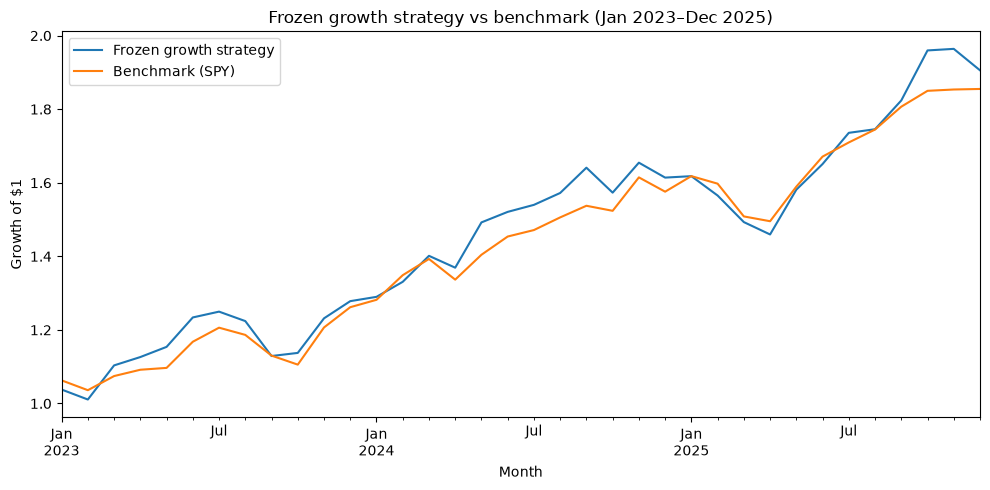

Outputs saved to: D:\FirstProjectPython\outputs

Files:
- annual_bond_cashflows.csv
- bond_curve_shape_stress.csv
- bond_valuation_duration_convexity.csv
- candidate_universe.csv
- decision_log_template.csv
- environment_and_assumptions.json
- factor_regression_results.csv
- frozen_growth_strategy_weights.csv
- frozen_strategy_vs_benchmark.png
- frozen_strategy_vs_benchmark_2023_2025.csv
- inflation_goal_sensitivity.csv
- initial_funding_plan.csv
- portfolio_optimization_weights.csv
- risk_aversion_threshold_sensitivity.csv
- risk_return_preference_comparison.csv
- sample_coverage.csv


In [133]:
# Comparison plot: frozen growth sleeve vs benchmark wealth indices
wealth = pd.concat([
    (1+frozen_growth_eval).cumprod().rename("Frozen growth strategy"),
    (1+benchmark_eval).cumprod().rename(f"Benchmark ({FROZEN_BENCHMARK})")
], axis=1)
ax = wealth.plot(title="Frozen growth strategy vs benchmark (Jan 2023–Dec 2025)",
                 ylabel="Growth of $1", xlabel="Month", figsize=(10,5))
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(OUT / "frozen_strategy_vs_benchmark.png", dpi=160)
plt.show()

print("Outputs saved to:", OUT.resolve())
print("\nFiles:")
for p in sorted(OUT.iterdir()):
    print("-", p.name)